# Data splitting for training and validation

In [ ]:
import pandas as pd
news_600_sample = pd.read_csv('clean_data/2024_05_05_news_600_samples_each_category.csv')

In [ ]:
news_600_sample["title_description_content"] = (news_600_sample["title"] + " ") * 10 + (news_600_sample["description"] + " ") * 3  + news_600_sample["content"]

In [ ]:
class_names = news_600_sample.category.to_list()

In [ ]:
news_600_sample["title_description_content"].to_list()

['hành_trình công_lý gái gốc việt vũ_trụ hành_trình công_lý gái gốc việt vũ_trụ hành_trình công_lý gái gốc việt vũ_trụ hành_trình công_lý gái gốc việt vũ_trụ hành_trình công_lý gái gốc việt vũ_trụ hành_trình công_lý gái gốc việt vũ_trụ hành_trình công_lý gái gốc việt vũ_trụ hành_trình công_lý gái gốc việt vũ_trụ hành_trình công_lý gái gốc việt vũ_trụ hành_trình công_lý gái gốc việt vũ_trụ xâm_hại amanda ngọc nguyễn đấu_tranh quyền nạn_nhân tấn_công tình_dục mỹ chinh_phục ước_mơ phi_hành_gia xâm_hại amanda ngọc nguyễn đấu_tranh quyền nạn_nhân tấn_công tình_dục mỹ chinh_phục ước_mơ phi_hành_gia xâm_hại amanda ngọc nguyễn đấu_tranh quyền nạn_nhân tấn_công tình_dục mỹ chinh_phục ước_mơ phi_hành_gia amanda ngọc nguyễn phụ_nữ gốc việt bay vũ_trụ chuyến phóng tên_lửa new shepard tập_đoàn hàng vũ_trụ blue origin chuyến bay tổ_chức phi lợi_nhuận space for humanity s4h mỹ tài_trợ diện chương_trình phi_hành_gia_công_dân ảnh_hưởng tầng_lớp xã_hội mỹ quê ngoại amanda bạc liêu sinh 1991 bang califor

In [ ]:
class_names = list(set(news_600_sample.category.to_list()))
# save class names
with open('class_names.txt', 'w') as f:
    for item in class_names:
        f.write("%s\n" % item)

In [ ]:
def class_name_to_id(class_name):
    return list(class_names).index(class_name)

In [ ]:
news_600_sample['category_id'] = news_600_sample['category'].apply(class_name_to_id)

In [ ]:
documents = news_600_sample.title_description_content.to_list()
categories_id = news_600_sample.category_id.to_list()

In [ ]:
# save documents and categories_id

with open('documents.txt', 'w') as f:
    for item in documents:
        f.write("%s\n" % item)

with open('categories_id.txt', 'w') as f:
    for item in categories_id:
        f.write("%s\n" % item)

In [ ]:
from sklearn.model_selection import train_valid_split
X_train, X_valid, y_train, y_valid = train_valid_split(documents, categories_id, valid_size=0.2, stratify=categories_id, random_state=42)
# save X_train, X_valid, y_train, y_valid

with open('X_train.txt', 'w') as f:
    for item in X_train:
        f.write("%s\n" % item)

with open('X_valid.txt', 'w') as f:
    for item in X_valid:
        f.write("%s\n" % item)

with open('y_train.txt', 'w') as f:
    for item in y_train:
        f.write("%s\n" % item)

with open('y_valid.txt', 'w') as f:
    for item in y_valid:
        f.write("%s\n" % item)

# Models

In [ ]:
!lscpu

Architecture:             x86_64
  CPU op-mode(s):         32-bit, 64-bit
  Address sizes:          46 bits physical, 48 bits virtual
  Byte Order:             Little Endian
CPU(s):                   2
  On-line CPU(s) list:    0,1
Vendor ID:                GenuineIntel
  Model name:             Intel(R) Xeon(R) CPU @ 2.20GHz
    CPU family:           6
    Model:                79
    Thread(s) per core:   2
    Core(s) per socket:   1
    Socket(s):            1
    Stepping:             0
    BogoMIPS:             4400.39
    Flags:                fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 cl
                          flush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc re
                          p_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3
                           fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand
                           hypervisor lahf_lm abm 3dnowprefetch i

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

In [ ]:
def plot_cm(confusion_mt):
  df_confusion_mt = pd.DataFrame(confusion_mt, index=class_names, columns=class_names)
  ax = sn.heatmap(df_confusion_mt, annot=True, fmt='g', cmap='Blues')
  ax.set_xlabel("Predicted", fontsize=12)
  ax.set_xticklabels(class_names, rotation=45)
  ax.set_ylabel("Target", fontsize=12)

Tải bộ dữ liệu đã được split

In [ ]:
!gdown 1l9NPdoPxtuev4iMzyJLT-ikHAR0xCJrz # download classes.txt

# download splitted dataset
!gdown 1kW5mSxxzCyKvV3EWttHYDlPVeGaTPewu
!gdown 1kzE3mJWn565SwhYqpQAv3ZN33gY0pQwI
!gdown 1kfNLxm5niASSaw7GvcVTfXxUjaSJDzmW
!gdown 1kfYbOIF2RlLHH9zrf5TIMYCNtMeTors4

Downloading...
From: https://drive.google.com/uc?id=1l9NPdoPxtuev4iMzyJLT-ikHAR0xCJrz
To: /content/class_names.txt
100% 98.0/98.0 [00:00<00:00, 341kB/s]
Downloading...
From: https://drive.google.com/uc?id=1kW5mSxxzCyKvV3EWttHYDlPVeGaTPewu
To: /content/X_valid.txt
100% 3.35M/3.35M [00:00<00:00, 62.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1kzE3mJWn565SwhYqpQAv3ZN33gY0pQwI
To: /content/X_train.txt
100% 13.3M/13.3M [00:00<00:00, 53.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1kfNLxm5niASSaw7GvcVTfXxUjaSJDzmW
To: /content/y_train.txt
100% 7.64k/7.64k [00:00<00:00, 16.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1kfYbOIF2RlLHH9zrf5TIMYCNtMeTors4
To: /content/y_valid.txt
100% 1.91k/1.91k [00:00<00:00, 4.76MB/s]


In [ ]:
X_train = []
with open('X_train.txt', 'r') as f:
    for line in f:
        X_train.append(line.strip())

X_valid = []
with open('X_valid.txt', 'r') as f:
    for line in f:
        X_valid.append(line.strip())

y_train = []
with open('y_train.txt', 'r') as f:
    for line in f:
        y_train.append(int(line.strip()))

y_valid = []
with open('y_valid.txt', 'r') as f:
    for line in f:
        y_valid.append(int(line.strip()))

class_names = []
with open('class_names.txt', 'r') as f:
    for line in f:
        class_names.append(line.strip())

Thống kê kích thước bộ dữ liệu

In [ ]:
len(X_train), len(X_valid), len(y_train), len(y_valid)

(3820, 956, 3820, 956)

<ipython-input-7-afece3a6a3f6>:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(train_count.keys()), y=list(train_count.values()), ax=ax[0], palette='tab10')
<ipython-input-7-afece3a6a3f6>:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=45)
<ipython-input-7-afece3a6a3f6>:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(valid_count.keys()), y=list(valid_count.values()), ax=ax[1], palette='tab10')
<ipython-input-7-afece3a6a3f6>:30: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45)


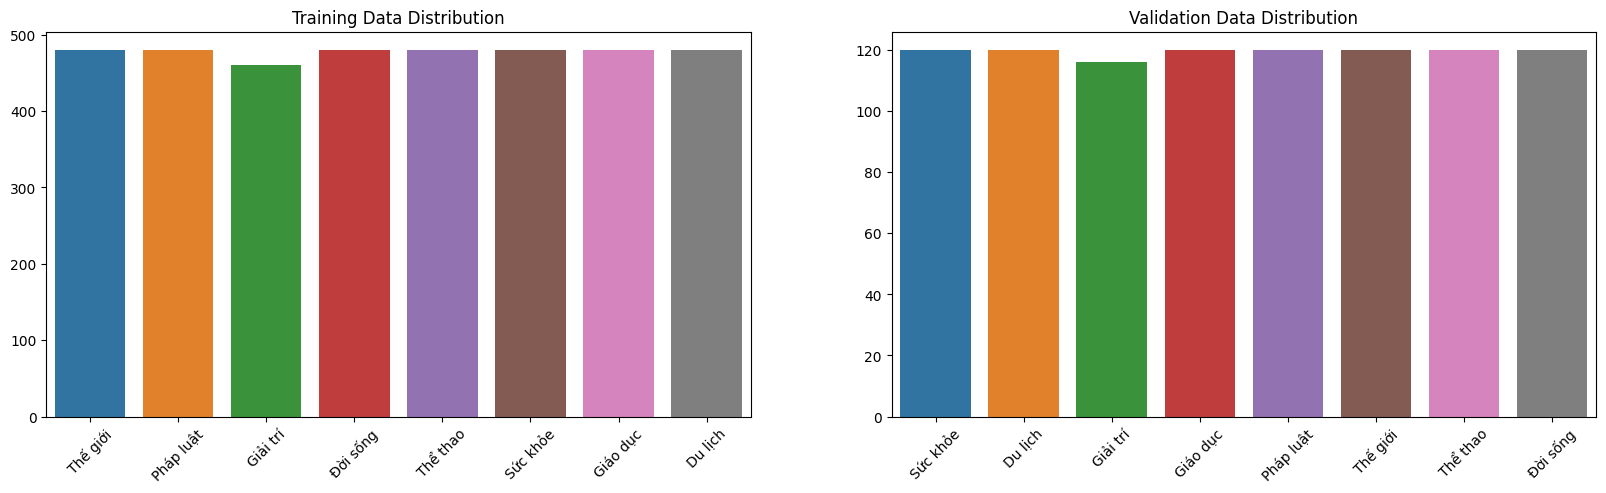

In [ ]:
# plot distribution of training and validation data
import matplotlib.pyplot as plt
import seaborn as sns

# count number of samples in each category

train_count = {}
for i in y_train:
    if i not in train_count:
        train_count[i] = 1
    else:
        train_count[i] += 1

valid_count = {}
for i in y_valid:
    if i not in valid_count:
        valid_count[i] = 1
    else:
        valid_count[i] += 1

train_count = {class_names[k]: v for k, v in train_count.items()}
valid_count = {class_names[k]: v for k, v in valid_count.items()}

fig, ax = plt.subplots(1, 2, figsize=(20, 5))
sns.barplot(x=list(train_count.keys()), y=list(train_count.values()), ax=ax[0], palette='tab10')
ax[0].set_title("Training Data Distribution")
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=45)
sns.barplot(x=list(valid_count.keys()), y=list(valid_count.values()), ax=ax[1], palette='tab10')
ax[1].set_title("Validation Data Distribution")
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45)
plt.show()

## 1. Multinomial Naive Bayes

### 1.1 Vector hóa dữ liệu

In [ ]:
# featurizer = CountVectorizer()
featurizer = TfidfVectorizer(min_df=3)

X_train_feat = featurizer.fit_transform(X_train)
X_valid_feat = featurizer.transform(X_valid)

Số chiều của vector đặc trưng

In [ ]:
voca_dict = featurizer.vocabulary_
len(voca_dict)

16455

### 1.2 Huấn luyện mô hình

In [ ]:
mNB = MultinomialNB()
mNB.fit(X_train_feat, y_train)

MultinomialNB()

### 1.3 Đánh giá mô hình

Quan sát dựa vào các metrics khác (precision, recall, f1 score, ...)

In [ ]:
%time
y_pred = model.predict(X_valid_feat)
print(classification_report(y_valid, y_pred, target_names=class_names))

CPU times: user 4 µs, sys: 0 ns, total: 4 µs
Wall time: 7.87 µs
              precision    recall  f1-score   support

    Giải trí       0.93      0.93      0.93       116
    Đời sống       0.86      0.68      0.76       120
    Thể thao       0.99      0.95      0.97       120
    Thế giới       0.99      0.90      0.94       120
     Du lịch       0.85      0.97      0.91       120
   Pháp luật       0.94      0.97      0.96       120
    Giáo dục       0.94      0.94      0.94       120
    Sức khỏe       0.84      0.97      0.90       120

    accuracy                           0.92       956
   macro avg       0.92      0.92      0.91       956
weighted avg       0.92      0.92      0.91       956



Ma trận nhầm lẫn

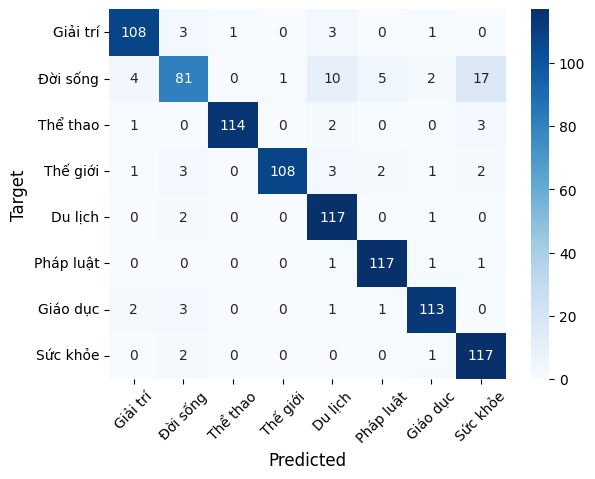

In [ ]:
plot_cm(confusion_matrix(y_valid, y_pred))

In [ ]:
# import f1_score, accuracy_score, confusion_matrix

from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_valid, y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_valid, y_pred)
print(f"accuracy: {acc:.4f}")

f1 score: 0.9135
accuracy: 0.9153


## 2. Random Forest

### 2.1. Vector hóa dữ liệu

Sử dụng TF-IDF <br>
min_df = 3: chỉ tính những từ khóa xuất hiện ở ít nhất 3 tài liệu

In [ ]:
vectorizer = TfidfVectorizer(min_df=3)
X_train_features = vectorizer.fit_transform(X_train)
X_valid_features = vectorizer.transform(X_valid)

Số chiều của vector đặc trưng

In [ ]:
voca_dict = vectorizer.vocabulary_
len(voca_dict)

16455

### 2.2. Huấn luyện mô hình

In [ ]:
clf_rdforest = RandomForestClassifier(n_estimators=100, criterion="gini", random_state=42)  # Set the number of trees as 100
clf_rdforest.fit(X_train_features, y_train)

RandomForestClassifier(random_state=42)

### 2.3. Kết quả dự đoán

In [ ]:
print(f"Train acc: {clf_rdforest.score(X_train_features, y_train):.3f}")
print(f"valid acc: {clf_rdforest.score(X_valid_features, y_valid):.3f}")

Train acc: 1.000
valid acc: 0.932


In [ ]:
%time
y_pred = clf_rdforest.predict(X_valid_features)

CPU times: user 5 µs, sys: 0 ns, total: 5 µs
Wall time: 8.58 µs


In [ ]:
print(classification_report(y_valid, y_pred, target_names=class_names))

              precision    recall  f1-score   support

    Giải trí       0.92      0.94      0.93       116
    Đời sống       0.83      0.77      0.80       120
    Thể thao       1.00      0.96      0.98       120
    Thế giới       1.00      0.92      0.96       120
     Du lịch       0.92      0.93      0.93       120
   Pháp luật       0.94      0.98      0.96       120
    Giáo dục       0.97      0.98      0.98       120
    Sức khỏe       0.89      0.97      0.93       120

    accuracy                           0.93       956
   macro avg       0.93      0.93      0.93       956
weighted avg       0.93      0.93      0.93       956



In [ ]:
# import f1_score, accuracy_score, confusion_matrix

from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_valid, y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_valid, y_pred)
print(f"accuracy: {acc:.4f}")

f1 score: 0.9315
accuracy: 0.9320


Ma trận nhầm lẫn

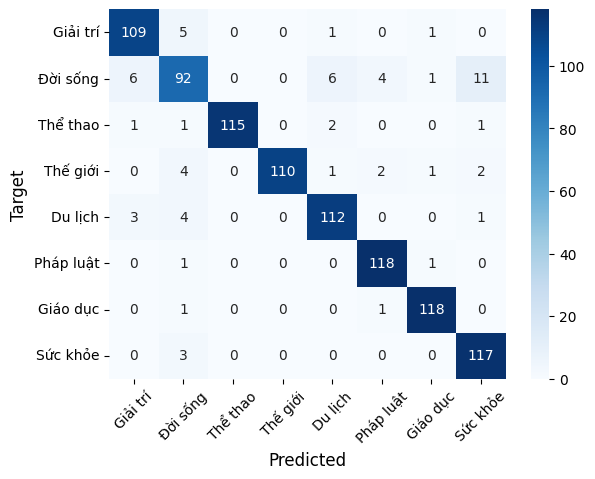

In [ ]:
plot_cm(confusion_matrix(y_valid, y_pred))

## 3. Multinomial Logistic Regression (Softmax Regression)


Multinomial Logistic Regression (Hồi quy Logistic đa thức) có tên gọi khác là hồi quỳ Softmax (`Softmax Regression`) là một mô hình dựa trên `Logistic Regression` sử dụng cho dự đoán để phân lớp 2 nhãn nhưng mở rộng ra cho nhiều nhãn.

$y = \sigma(W^Tx)$

Trong đó:

* $\sigma()$ là hàm kích hoạt
* $W$ là trọng số của các features có được sau quá trình tìm được từ huấn luyện dữ liệu
* $x$ là dữ liệu đầu vào, cụ thể là các features.
----
Để tính toán trên bài toán đa lớp ta cần thiết lập một số điều như sau:

* $W \in R^{N \times M}$, trong đó $N$ tương ứng với số chiều dữ liệu đầu vào, $M$ tương ứng với số lượng nhãn yêu cầu ở đầu ra.

* $x \in R^{N \times 1}$, $x$ là một vector có số lượng phần tử là $N$.

* $\sigma()$, hàm kích hoạt sẽ sử dụng hàm phân phối `Softmax`
---
Lúc này ta có thể dễ dàng nhận ra, khi $W^Tx$ thì đầu ra sẽ là một vector có chiều $M$, cụ thể: $(R^{N \times M})^T \cdot R^{N \times 1} → R^{M \times 1}$


In [ ]:
import numpy as np

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import pandas as pd
def plot_cm(confusion_mt):
  df_confusion_mt = pd.DataFrame(confusion_mt, index=class_names, columns=class_names)
  ax = sns.heatmap(df_confusion_mt, annot=True, fmt='g', cmap='Blues')
  ax.set_xlabel("Predicted", fontsize=12)
  ax.set_xticklabels(class_names, rotation=45)
  ax.set_ylabel("Target", fontsize=12)
  plt.show()

In [ ]:
X_train = []
with open('X_train.txt', 'r') as f:
    for line in f:
        X_train.append(line.strip())

X_valid = []
with open('X_valid.txt', 'r') as f:
    for line in f:
        X_valid.append(line.strip())

y_train = []
with open('y_train.txt', 'r') as f:
    for line in f:
        y_train.append(int(line.strip()))

y_valid = []
with open('y_valid.txt', 'r') as f:
    for line in f:
        y_valid.append(int(line.strip()))

class_names = []
with open('class_names.txt', 'r') as f:
    for line in f:
        class_names.append(line.strip())

### 3.1. Phương pháp vector hóa đặc trưng

Phương pháp được mô phỏng theo phương pháp features hashing được trình bày trên Wikipedia (https://en.wikipedia.org/wiki/Feature_hashing). Tuy nhiên có thay đổi hàm `hash` có sẵn trong Python thành chỉ số của từ trong từ điển.

Quá trình xây dựng từ điển chỉ diễn ra ở quá trình huấn luyện

In [ ]:
def hashing_vectorizer(documents, num_features, feat_dict=None):
    hashed_vectors = []
    if feat_dict is None:
        feature_dict = {}
    else:
        feature_dict = feat_dict.copy()

    for document in documents:
        words = document.split()

        vector = [0] * num_features
        for word in words:
            if word not in feature_dict:
                feature_dict[word] = len(feature_dict.keys())
            feature_index = feature_dict[word] % num_features
            vector[feature_index] += 1

        hashed_vectors.append(vector)
    return hashed_vectors, feature_dict

### 3.2. Huấn luyện mô hình

Huấn luyện mô hình, nhóm sử dụng hàm mất mát được xây dựng từ hàm `log likelihood`, cụ thể như sau:

$$
\text{Negative Log-Likelihood}_i = -\log(y_{\text{pred}}[i, y_{\text{true}}[i]])\\
\text{Loss} = \frac{1}{m} \sum_{i=1}^{m} \text{Negative Log-Likelihood}_i
$$

Hàm grad được cụ thể hóa như sau

$$
Grad = \frac{1}{m} X^T \cdot (y_{pred} - onehot(y_{true}))
$$

----
Trong đó:

* $y_{pred}$ là phân phối xác suất dự đoán của mô hình với 8 nhãn.

* $y_{true}$ là nhãn thực tế của dữ liệu đầu vào, nhãn này có các giá trị thuộc trong các số: {0, 1, 2, 3, 4, 5, 6, 7}

* $X$ là dữ liệu đầu vào
* Hàm onehot là hàm mã hóa lại giá trị của $y_{true}$ thành một vector gồm số 0 và số 1, cụ thể các giá trị tại các nhãn khác bằng 0, còn tại vị trí $y_{true}$ thì bằng 1, ví dụ: $y_{true} = 3$ thì vector sẽ là $[0, 0, 0, 1, 0, 0, 0, 0]$
* $m$ là số mẫu được đưa vào



In [ ]:
# Logistic Regression for multi-classification
from tqdm import tqdm

class LogisticRegression:
    def __init__(self, learning_rate=0.01, num_iter=1000):
        self.learning_rate = learning_rate
        self.num_iter = num_iter
        self.weights = None

    def softmax(self, z):
        return np.exp(z) / np.sum(np.exp(z), axis=1, keepdims=True)

    def cross_entropy_loss(self, y_pred, y_true):
        m = y_true.shape[0]
        log_likelihood = -np.log(y_pred[range(m), y_true])
        loss = np.sum(log_likelihood) / m
        return loss

    def fit(self, X, y, batch_size=32):
        m, n = X.shape

        if self.weights is None:
            self.weights = np.zeros((n, len(np.unique(y))))

        pbar = tqdm(range(self.num_iter), bar_format='{desc} {percentage:3.0f}%|{bar:10}{r_bar}')
        for i in pbar:
            # Data Shuffling
            idx = np.random.permutation(m)
            X = X[idx]
            y = y[idx]

            losses = []
            for j in range(0, m, batch_size):
                X_batch = X[j:j+batch_size]
                y_batch = y[j:j+batch_size]

                z = np.dot(X_batch, self.weights)
                y_pred = self.softmax(z)
                loss = self.cross_entropy_loss(y_pred, y_batch)
                losses.append(loss)
                gradient = np.dot(X_batch.T, (y_pred - np.eye(len(np.unique(y)))[y_batch])) / m
                self.weights -= self.learning_rate * gradient

            pbar.set_description(f"Epoch {i + 1}")
            pbar.set_postfix({"loss":np.mean(losses)})

    def save_weights(self, file_name):
        np.save(file_name, self.weights)

    def load_weights(self, file_name):
        self.weights = np.load(file_name)

    def predict(self, X):
        z = np.dot(X, self.weights)
        return self.softmax(z)

**Trường hợp quá trình huấn luyện bị gián đoạn do số lượng features quá lớn**

In [ ]:
import pickle

num_features = [60000]
for num_fea in num_features:
    X_train_hashed, feature_dict = hashing_vectorizer(X_train, num_fea)
    X_valid_hashed, _ = hashing_vectorizer(X_valid, num_fea, feature_dict.copy())

    # save feature_dict
    with open(f'feature_dict_{num_fea}.pkl', 'wb') as f:
        pickle.dump(feature_dict, f)

    LR = LogisticRegression(learning_rate=0.1, num_iter=1000)
    X_train_hashed = np.array(X_train_hashed)
    y_train = np.array(y_train)
    LR.fit(X_train_hashed, y_train, batch_size=1)

    y_pred = LR.predict(np.array(X_valid_hashed))
    y_pred = np.argmax(y_pred, axis=1)
    report = classification_report(y_valid, y_pred, target_names=class_names)
    print(f'Number of features: {num_fea}')
    print(report)

    cm = confusion_matrix(y_valid, y_pred)
    plot_cm(cm)

    LR.save_weights(f'saved_models/LogisticRegressionModel_{num_fea}.npy')

   0%|          | 0/1000 [00:00<?, ?it/s]

: 

: 

: 

Epoch 1000:  100%|██████████| 1000/1000 [01:15<00:00, 13.28it/s, loss=0.0198]


Number of features: 512
              precision    recall  f1-score   support

    Giải trí       0.75      0.83      0.79       116
    Đời sống       0.57      0.61      0.59       120
    Thể thao       0.95      0.93      0.94       120
    Thế giới       0.92      0.85      0.88       120
     Du lịch       0.78      0.76      0.77       120
   Pháp luật       0.82      0.82      0.82       120
    Giáo dục       0.92      0.87      0.89       120
    Sức khỏe       0.81      0.82      0.81       120

    accuracy                           0.81       956
   macro avg       0.81      0.81      0.81       956
weighted avg       0.81      0.81      0.81       956



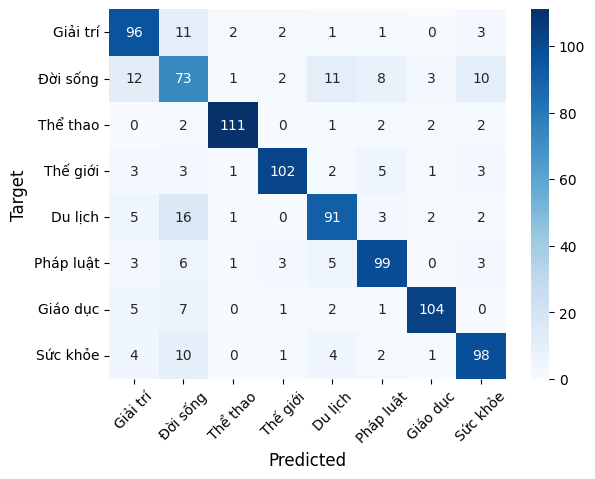

Epoch 1000:  100%|██████████| 1000/1000 [01:34<00:00, 10.59it/s, loss=0.00867]


Number of features: 1024
              precision    recall  f1-score   support

    Giải trí       0.91      0.91      0.91       116
    Đời sống       0.67      0.75      0.71       120
    Thể thao       0.95      0.96      0.95       120
    Thế giới       0.95      0.85      0.90       120
     Du lịch       0.86      0.83      0.85       120
   Pháp luật       0.88      0.91      0.89       120
    Giáo dục       0.93      0.93      0.93       120
    Sức khỏe       0.89      0.88      0.88       120

    accuracy                           0.88       956
   macro avg       0.88      0.88      0.88       956
weighted avg       0.88      0.88      0.88       956



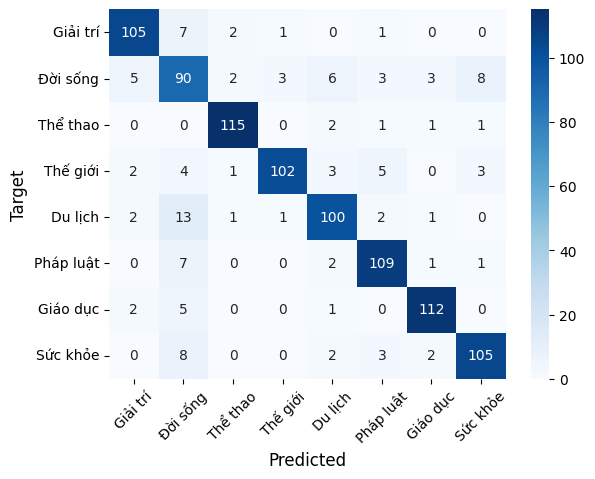

Epoch 1000:  100%|██████████| 1000/1000 [02:56<00:00,  5.66it/s, loss=0.00592]


Number of features: 2048
              precision    recall  f1-score   support

    Giải trí       0.92      0.93      0.92       116
    Đời sống       0.66      0.77      0.71       120
    Thể thao       0.96      0.97      0.97       120
    Thế giới       0.97      0.88      0.92       120
     Du lịch       0.89      0.84      0.86       120
   Pháp luật       0.92      0.96      0.94       120
    Giáo dục       0.97      0.95      0.96       120
    Sức khỏe       0.91      0.86      0.88       120

    accuracy                           0.89       956
   macro avg       0.90      0.89      0.90       956
weighted avg       0.90      0.89      0.90       956



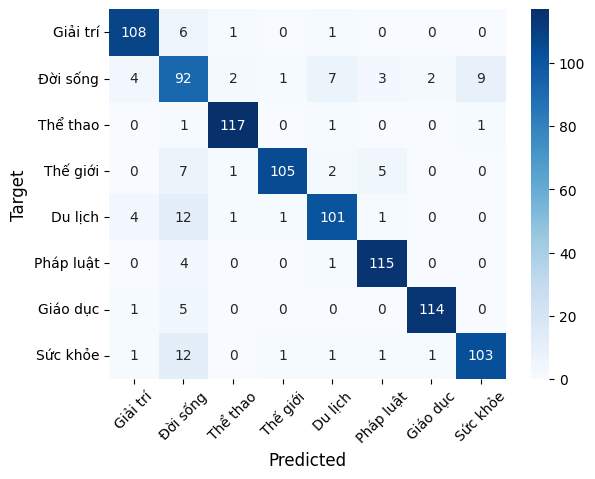

Epoch 1000:  100%|██████████| 1000/1000 [05:27<00:00,  3.05it/s, loss=0.00497]


Number of features: 4096
              precision    recall  f1-score   support

    Giải trí       0.90      0.93      0.92       116
    Đời sống       0.73      0.76      0.75       120
    Thể thao       0.97      0.97      0.97       120
    Thế giới       0.96      0.89      0.92       120
     Du lịch       0.88      0.87      0.87       120
   Pháp luật       0.93      0.97      0.95       120
    Giáo dục       0.98      0.96      0.97       120
    Sức khỏe       0.91      0.91      0.91       120

    accuracy                           0.91       956
   macro avg       0.91      0.91      0.91       956
weighted avg       0.91      0.91      0.91       956



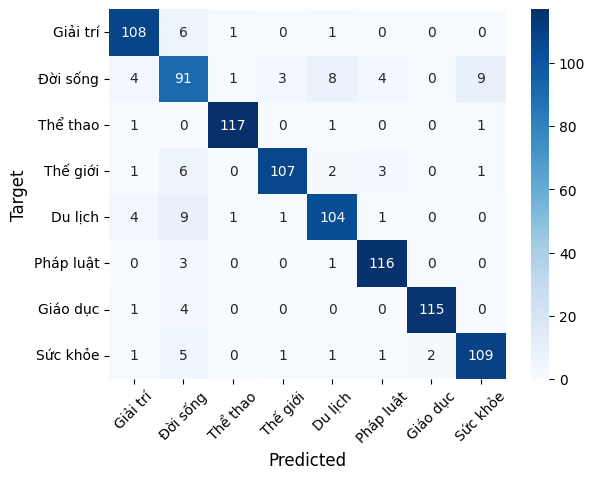

Epoch 1000:  100%|██████████| 1000/1000 [08:04<00:00,  2.06it/s, loss=0.00466]


Number of features: 8192
              precision    recall  f1-score   support

    Giải trí       0.92      0.94      0.93       116
    Đời sống       0.76      0.81      0.78       120
    Thể thao       0.97      0.97      0.97       120
    Thế giới       0.99      0.92      0.95       120
     Du lịch       0.88      0.88      0.88       120
   Pháp luật       0.97      0.97      0.97       120
    Giáo dục       0.98      0.96      0.97       120
    Sức khỏe       0.92      0.93      0.92       120

    accuracy                           0.92       956
   macro avg       0.92      0.92      0.92       956
weighted avg       0.92      0.92      0.92       956



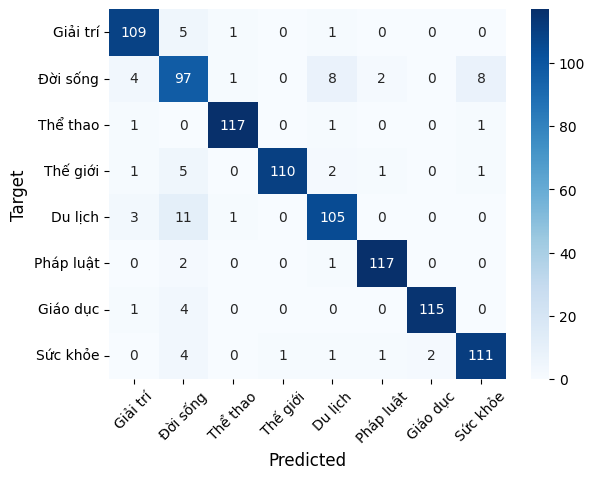

Epoch 1000:  100%|██████████| 1000/1000 [11:02<00:00,  1.51it/s, loss=0.00457]


Number of features: 16384
              precision    recall  f1-score   support

    Giải trí       0.92      0.95      0.93       116
    Đời sống       0.76      0.78      0.77       120
    Thể thao       0.97      0.97      0.97       120
    Thế giới       0.98      0.92      0.95       120
     Du lịch       0.88      0.88      0.88       120
   Pháp luật       0.98      0.98      0.98       120
    Giáo dục       0.98      0.96      0.97       120
    Sức khỏe       0.91      0.93      0.92       120

    accuracy                           0.92       956
   macro avg       0.92      0.92      0.92       956
weighted avg       0.92      0.92      0.92       956



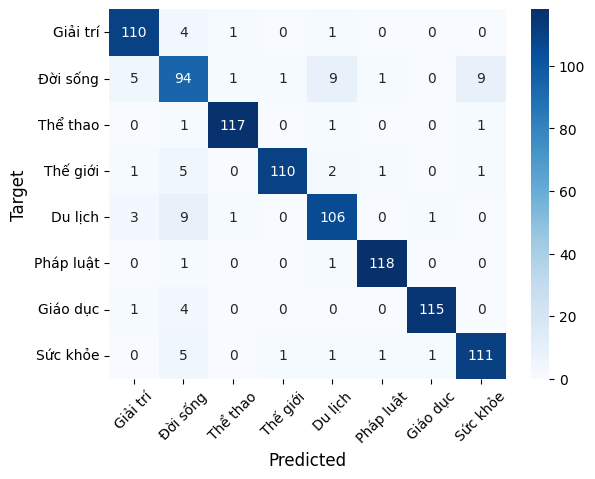

In [ ]:
import pickle

num_features = [512, 1024, 2048, 4096, 8192, 16384]
for num_fea in num_features:
    X_train_hashed, feature_dict = hashing_vectorizer(X_train, num_fea)
    X_valid_hashed, _ = hashing_vectorizer(X_valid, num_fea, feature_dict.copy())

    # save feature_dict
    with open(f'feature_dict_{num_fea}.pkl', 'wb') as f:
        pickle.dump(feature_dict, f)

    LR = LogisticRegression(learning_rate=0.1, num_iter=1000)
    X_train_hashed = np.array(X_train_hashed)
    y_train = np.array(y_train)
    LR.fit(X_train_hashed, y_train)

    y_pred = LR.predict(np.array(X_valid_hashed))
    y_pred = np.argmax(y_pred, axis=1)
    report = classification_report(y_valid, y_pred, target_names=class_names)
    print(f'Number of features: {num_fea}')
    print(report)

    cm = confusion_matrix(y_valid, y_pred)
    plot_cm(cm)

    LR.save_weights(f'saved_models/LogisticRegressionModel_{num_fea}.npy')

### 3.3. Kiểm thử mô hình

In [ ]:
import pickle
feature_dict = {}
with open('feature_dict_8192.pkl', 'rb') as f:
    feature_dict = pickle.load(f)

In [ ]:
X_valid_hashed, _ = hashing_vectorizer(X_valid, 8192, feature_dict)

In [ ]:
print(X_valid_hashed[0])

[0, 1, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 11, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

CPU times: user 4 µs, sys: 0 ns, total: 4 µs
Wall time: 7.15 µs
              precision    recall  f1-score   support

    Giải trí       0.92      0.94      0.93       116
    Đời sống       0.76      0.81      0.78       120
    Thể thao       0.97      0.97      0.97       120
    Thế giới       0.99      0.92      0.95       120
     Du lịch       0.88      0.88      0.88       120
   Pháp luật       0.97      0.97      0.97       120
    Giáo dục       0.98      0.96      0.97       120
    Sức khỏe       0.92      0.93      0.92       120

    accuracy                           0.92       956
   macro avg       0.92      0.92      0.92       956
weighted avg       0.92      0.92      0.92       956



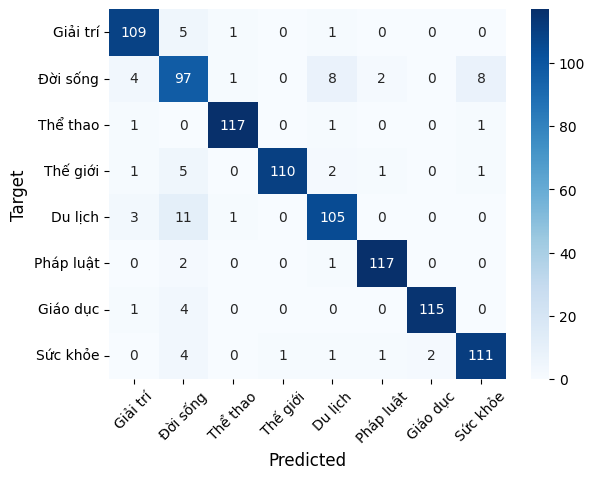

In [ ]:
model = LogisticRegression()
model.load_weights("LogisticRegressionModel_8192.npy")
X_valid_hashed, _ = hashing_vectorizer(X_valid, 8192, feature_dict.copy())
%time
y_pred = model.predict(np.array(X_valid_hashed))
y_pred = np.argmax(y_pred, axis=1)
report = classification_report(y_valid, y_pred, target_names=class_names)
print(report)

cm = confusion_matrix(y_valid, y_pred)
plot_cm(cm)

In [ ]:
# import f1_score, accuracy_score, confusion_matrix

from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_valid, y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_valid, y_pred)
print(f"accuracy: {acc:.4f}")

f1 score: 0.9223
accuracy: 0.9215


In [ ]:
example = """Thanh Hóa đứng đầu về doanh thu và lượng khách dịp lễ 30/4 nhờ lợi thế về văn hóa, tự nhiên và chính sách, nhưng kết quả còn khiêm tốn so với tiềm năng, theo giới chức tỉnh.
Theo số liệu từ Tổng cục Du lịch, kỳ nghỉ lễ 30/4-1/5, Thanh Hóa là địa phương đón đông khách nhất trong cả nước với trên 1,5 triệu lượt - con số kỷ lục, tăng hơn 27% so với cùng kỳ. Lượng khách đến Thanh Hóa gấp gần ba lần của Hà Tĩnh và gần bằng tổng của cả hai tỉnh Nghệ An, Hà Tĩnh gộp lại. Tổng doanh thu du lịch của địa phương dịp lễ đạt hơn 3.800 tỷ đồng, tăng gần 33% so với 2023.
"""

In [ ]:
import nltk
from nltk.tokenize import sent_tokenize
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     /home/nguyenhung1903/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [ ]:
# read stopwords file
with open("custom_stopwords_vn.txt", "r") as f:
    stopwords = f.read().split("\n")

print(stopwords)

['bị', 'bởi', 'cả', 'các', 'cái', 'cần', 'càng', 'chỉ', 'chiếc', 'cho', 'chứ', 'chưa', 'chuyện', 'có', 'có_thể', 'cứ', 'của', 'cùng', 'cũng', 'đã', 'đang', 'đây', 'để', 'đến_nỗi', 'đều', 'điều', 'do', 'đó', 'được', 'dưới', 'gì', 'khi', 'không', 'là', 'lại', 'lên', 'lúc', 'mà', 'mỗi', 'một_cách', 'này', 'nên', 'nếu', 'ngay', 'nhiều', 'như', 'nhưng', 'những', 'nơi', 'nữa', 'phải', 'qua', 'ra', 'rằng', 'rằng', 'rất', 'rất', 'rồi', 'sau', 'sẽ', 'so', 'sự', 'tại', 'theo', 'thì', 'trên', 'trước', 'từ', 'từng', 'và', 'vẫn', 'vào', 'vậy', 'vì', 'việc', 'với', 'vừa']


In [ ]:
def remove_stopwords(text):
    return " ".join([word for word in text.split() if word not in stopwords])

In [ ]:
import re
from pyvi import ViTokenizer

def text_processing(text):
    sentences = sent_tokenize(text)
    sentences = [re.sub(r'[^\w\s]', '', text) for text in sentences]
    sentences = [ViTokenizer.tokenize(text) for text in sentences]
    sentences = [remove_stopwords(text) for text in sentences]
    sentences = [text.lower() for text in sentences]

    return " ".join(sentences)

In [ ]:
class_names

['Giải trí',
 'Đời sống',
 'Thể thao',
 'Thế giới',
 'Du lịch',
 'Pháp luật',
 'Giáo dục',
 'Sức khỏe']

In [ ]:
text_processing(example)

'thanh_hóa đứng đầu về doanh_thu lượng khách dịp lễ 304 nhờ lợi_thế về văn_hóa tự_nhiên chính_sách kết_quả còn khiêm_tốn tiềm_năng giới_chức tỉnh theo số_liệu tổng_cục du_lịch kỳ nghỉ lễ 30415 thanh_hóa địa_phương đón đông khách nhất trong nước 15 triệu lượt con_số kỷ_lục tăng hơn 27 kỳ lượng khách đến thanh_hóa_gấp gần ba lần hà_tĩnh gần bằng tổng hai tỉnh nghệ_an hà_tĩnh gộp tổng_doanh_thu du_lịch địa_phương dịp lễ đạt hơn 3800 tỷ đồng tăng gần 33 2023'

In [ ]:
example_hashed, _ = hashing_vectorizer([text_processing(example)], 8192, feature_dict)

pred = model.predict(example_hashed)

for i in range(len(pred[0])):
    print(f'{class_names[i]}: {pred[0][i]}')

print(f'Predicted class: {class_names[np.argmax(pred[0])]}')

Giải trí: 0.07838217419728266
Đời sống: 0.13024045786229102
Thể thao: 0.0872557929366634
Thế giới: 0.06951784674676827
Du lịch: 0.36871045461535507
Pháp luật: 0.10560331863755436
Giáo dục: 0.0732348464483988
Sức khỏe: 0.08705510855568628
Predicted class: Du lịch


# Testing


In [ ]:
!gdown 192p1wAX5lKMH2acAINuU-ZbCs94cP9D9

Downloading...
From: https://drive.google.com/uc?id=192p1wAX5lKMH2acAINuU-ZbCs94cP9D9
To: /content/news_test_cleaned.csv
100% 3.96M/3.96M [00:00<00:00, 181MB/s]


In [ ]:
import pandas as pd
test_set = pd.read_csv('news_test_cleaned.csv')

In [ ]:
test_set = test_set.dropna()

In [ ]:
test_set["title_description_content"] = (test_set["title"] + " ") * 10 + (test_set["description"] + " ") * 3  + test_set["content"]

In [ ]:
test_set["title_description_content"].to_list()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
test_set.isnull().sum()

title                        0
description                  0
content                      0
author                       0
time                         0
link                         0
category                     0
title_description_content    0
dtype: int64

In [ ]:
class_names

['Giải trí',
 'Đời sống',
 'Thể thao',
 'Thế giới',
 'Du lịch',
 'Pháp luật',
 'Giáo dục',
 'Sức khỏe']

In [ ]:
def class_name_to_id(class_name):
    return list(class_names).index(class_name)

In [ ]:
test_set['category_id'] = test_set['category'].apply(class_name_to_id)

In [ ]:
X_test = test_set.title_description_content.to_list()
y_test = test_set.category_id.to_list()

In [ ]:
X_test

Output hidden; open in https://colab.research.google.com to view.

<ipython-input-45-477178a4b783>:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(train_count.keys()), y=list(train_count.values()), ax=ax[0], palette='tab10')
<ipython-input-45-477178a4b783>:35: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=45)
<ipython-input-45-477178a4b783>:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(valid_count.keys()), y=list(valid_count.values()), ax=ax[1], palette='tab10')
<ipython-input-45-477178a4b783>:38: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45)
<ipython-input-45-

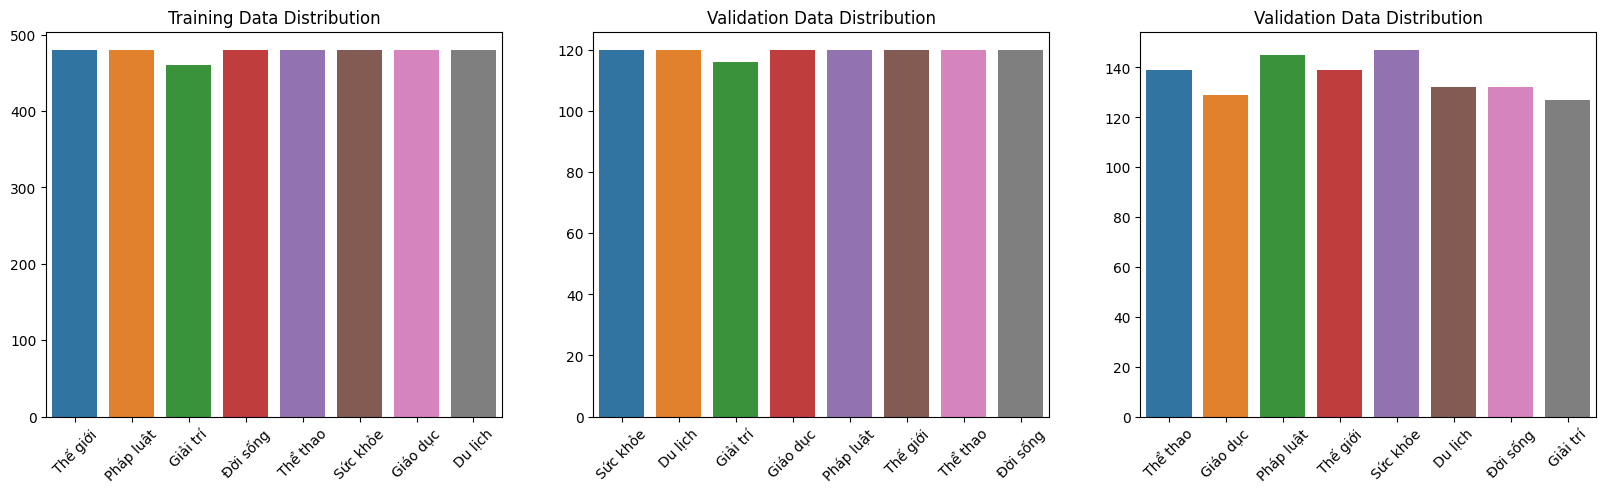

In [ ]:
# plot distribution of training and validation data
import matplotlib.pyplot as plt
import seaborn as sns

# count number of samples in each category

train_count = {}
for i in y_train:
    if i not in train_count:
        train_count[i] = 1
    else:
        train_count[i] += 1

valid_count = {}
for i in y_valid:
    if i not in valid_count:
        valid_count[i] = 1
    else:
        valid_count[i] += 1

test_count = {}
for i in y_test:
    if i not in test_count:
        test_count[i] = 1
    else:
        test_count[i] += 1

train_count = {class_names[k]: v for k, v in train_count.items()}
valid_count = {class_names[k]: v for k, v in valid_count.items()}
test_count = {class_names[k]: v for k, v in test_count.items()}

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sns.barplot(x=list(train_count.keys()), y=list(train_count.values()), ax=ax[0], palette='tab10')
ax[0].set_title("Training Data Distribution")
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=45)
sns.barplot(x=list(valid_count.keys()), y=list(valid_count.values()), ax=ax[1], palette='tab10')
ax[1].set_title("Validation Data Distribution")
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45)

sns.barplot(x=list(test_count.keys()), y=list(test_count.values()), ax=ax[2], palette='tab10')
ax[2].set_title("Validation Data Distribution")
ax[2].set_xticklabels(ax[2].get_xticklabels(), rotation=45)
plt.show()

In [ ]:
X_test_features = vectorizer.transform(X_test)

In [ ]:
clf_rdforest_y_pred = clf_rdforest.predict(X_test_features)

f1 score: 0.9013
accuracy: 0.9046
              precision    recall  f1-score   support

    Giải trí       0.90      0.94      0.92       127
    Đời sống       0.89      0.63      0.74       132
    Thể thao       0.95      0.98      0.96       139
    Thế giới       0.94      0.86      0.90       139
     Du lịch       0.87      0.95      0.91       132
   Pháp luật       0.94      0.97      0.96       145
    Giáo dục       0.86      0.97      0.91       129
    Sức khỏe       0.87      0.93      0.90       147

    accuracy                           0.90      1090
   macro avg       0.90      0.90      0.90      1090
weighted avg       0.91      0.90      0.90      1090



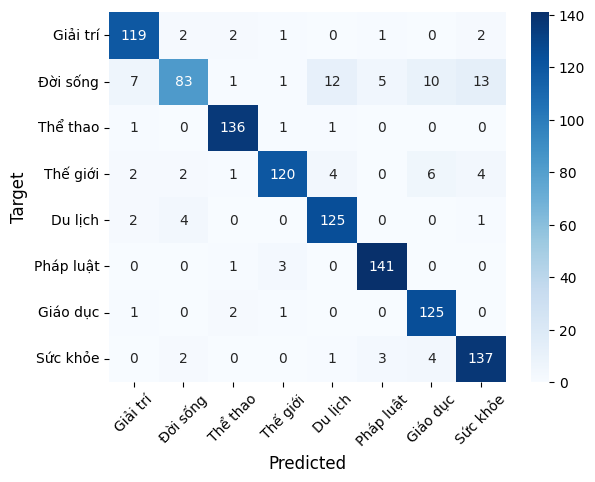

In [ ]:
from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_test, clf_rdforest_y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_test, clf_rdforest_y_pred)
print(f"accuracy: {acc:.4f}")
report = classification_report(y_test, clf_rdforest_y_pred, target_names=class_names)
print(report)
cm = confusion_matrix(y_test, clf_rdforest_y_pred)
plot_cm(cm)

In [ ]:
import pickle
feature_dict = {}
with open('feature_dict_16384.pkl', 'rb') as f:
    feature_dict = pickle.load(f)

accuracy: 0.9046
              precision    recall  f1-score   support

    Giải trí       0.95      0.94      0.94       127
    Đời sống       0.73      0.77      0.75       132
    Thể thao       0.96      0.98      0.97       139
    Thế giới       0.96      0.86      0.91       139
     Du lịch       0.86      0.89      0.88       132
   Pháp luật       0.95      0.95      0.95       145
    Giáo dục       0.92      0.95      0.93       129
    Sức khỏe       0.91      0.90      0.90       147

    accuracy                           0.90      1090
   macro avg       0.91      0.90      0.90      1090
weighted avg       0.91      0.90      0.90      1090



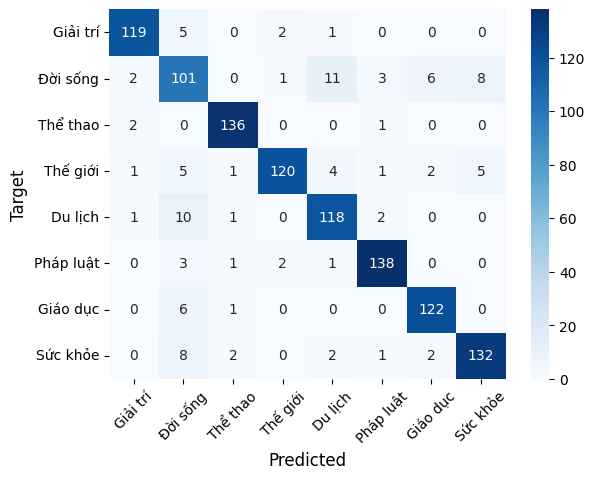

In [ ]:
LR = LogisticRegression()
LR.load_weights("LogisticRegressionModel_16384.npy")
X_test_hashed, _ = hashing_vectorizer(X_test, 16384, feature_dict.copy())
LR_y_pred = LR.predict(np.array(X_test_hashed))
LR_y_pred = np.argmax(LR_y_pred, axis=1)

# calculate accuracy
acc = accuracy_score(y_test, LR_y_pred)
print(f"accuracy: {acc:.4f}")
report = classification_report(y_test, LR_y_pred, target_names=class_names)
print(report)
cm = confusion_matrix(y_test, LR_y_pred)
plot_cm(cm)

In [ ]:
import pickle
feature_dict = {}
with open('feature_dict_8192.pkl', 'rb') as f:
    feature_dict = pickle.load(f)

accuracy: 0.9064
              precision    recall  f1-score   support

    Giải trí       0.98      0.93      0.95       127
    Đời sống       0.74      0.79      0.76       132
    Thể thao       0.96      0.99      0.97       139
    Thế giới       0.96      0.87      0.91       139
     Du lịch       0.86      0.87      0.87       132
   Pháp luật       0.91      0.95      0.93       145
    Giáo dục       0.93      0.95      0.94       129
    Sức khỏe       0.92      0.90      0.91       147

    accuracy                           0.91      1090
   macro avg       0.91      0.91      0.91      1090
weighted avg       0.91      0.91      0.91      1090



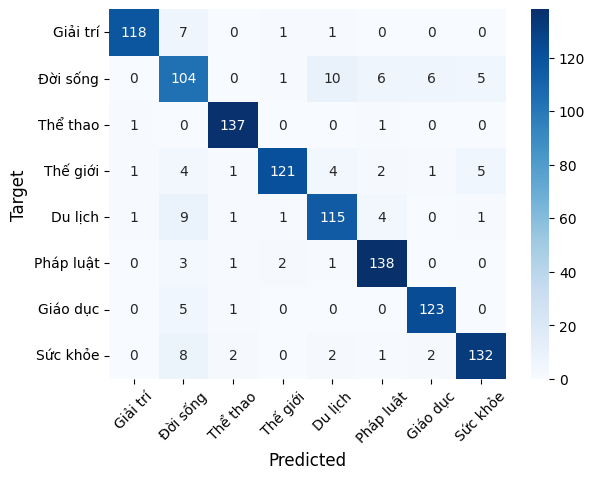

In [ ]:
LR = LogisticRegression()
LR.load_weights("LogisticRegressionModel_8192.npy")
X_test_hashed, _ = hashing_vectorizer(X_test, 8192, feature_dict.copy())
LR_y_pred = LR.predict(np.array(X_test_hashed))
LR_y_pred = np.argmax(LR_y_pred, axis=1)

# calculate accuracy
acc = accuracy_score(y_test, LR_y_pred)
print(f"accuracy: {acc:.4f}")
report = classification_report(y_test, LR_y_pred, target_names=class_names)
print(report)
cm = confusion_matrix(y_test, LR_y_pred)
plot_cm(cm)

In [ ]:
# import f1_score, accuracy_score, confusion_matrix

from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_test, LR_y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_test, LR_y_pred)
print(f"accuracy: {acc:.4f}")

f1 score: 0.9069
accuracy: 0.9064


accuracy: 0.9110
              precision    recall  f1-score   support

    Giải trí       0.96      0.94      0.95       127
    Đời sống       0.86      0.68      0.76       132
    Thể thao       0.96      0.99      0.98       139
    Thế giới       0.98      0.85      0.91       139
     Du lịch       0.82      0.92      0.87       132
   Pháp luật       0.92      0.97      0.94       145
    Giáo dục       0.90      0.97      0.93       129
    Sức khỏe       0.90      0.95      0.92       147

    accuracy                           0.91      1090
   macro avg       0.91      0.91      0.91      1090
weighted avg       0.91      0.91      0.91      1090



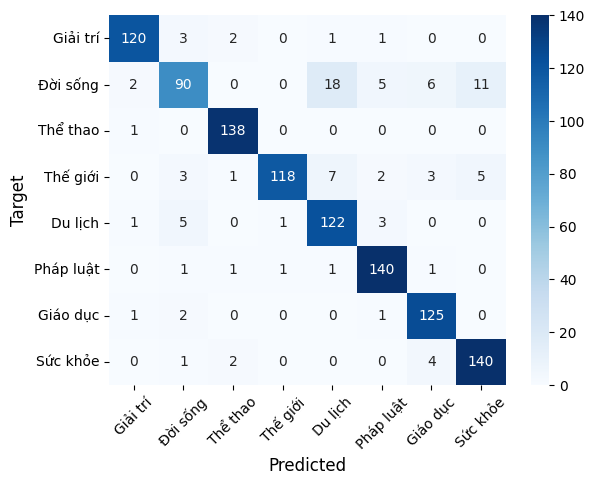

In [ ]:
mNB_y_pred = mNB.predict(X_test_features)
# calculate accuracy
acc = accuracy_score(y_test, mNB_y_pred)
print(f"accuracy: {acc:.4f}")
report = classification_report(y_test, mNB_y_pred, target_names=class_names)
print(report)
cm = confusion_matrix(y_test, mNB_y_pred)
plot_cm(cm)

In [ ]:
# import f1_score, accuracy_score, confusion_matrix

from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_test, mNB_y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_test, mNB_y_pred)
print(f"accuracy: {acc:.4f}")

f1 score: 0.9091
accuracy: 0.9110
